<a href="https://colab.research.google.com/github/panarisivalentino-pixel/prediccion-rendimiento-agricola-argentina/blob/main/notebooks/09_no_supervisado_zonas_agroclimaticas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje no supervisado: zonas agroclimáticas de Argentina y su integración al modelo de rendimiento

**Dataset:** `df_recortado.csv` (mismo del modelado supervisado)
**Objetivo:** aplicar reducción de dimensiones (PCA) y agrupamiento (clustering jerárquico y K-Means) sobre las variables climáticas para descubrir **zonas agroclimáticas** a partir de los datos, sin usar ninguna etiqueta, y luego evaluar si esa estructura aporta al modelo supervisado de `rendimiento_kgxha`.

Este notebook es complementario al entregable de aprendizaje supervisado. Allí la pregunta era *"¿cuánto rinde y qué lo determina?"* (hay variable objetivo → supervisado). Acá la pregunta es *"¿qué regiones climáticas existen en el país?"* (no hay etiqueta → no supervisado).

**Estructura**
1. PCA exploratorio del dataset completo
2. Preparación de datos para el clustering: unidad de análisis y escalado
3. Reducción de dimensiones con PCA sobre el clima departamental
4. Clustering jerárquico
5. K-Means: elección del número de clusters
6. Interpretación de las zonas agroclimáticas
7. Integración con el modelo supervisado
8. Conclusiones

In [ ]:
import warnings, time; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
import lightgbm as lgb

SEED = 42; np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep'); plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.3f}'.format

df = pd.read_csv('df_recortado.csv')
df['ALLSKY_SFC_SW_DWN'] = df['ALLSKY_SFC_SW_DWN'].replace(0, np.nan)   # 0 = dato faltante en 1981-1983
CLIMA = ['T2M', 'T2M_MAX', 'T2M_MIN', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'precip_total_mm']
print(df.shape)

(111417, 17)


## 1. PCA exploratorio del dataset completo

Antes de decidir qué agrupar, se aplica PCA sobre **todas las filas** del dataset (una por cultivo × departamento × año) con todas sus variables numéricas, siguiendo el orden del material de clase: escalar → PCA → interpretar → recién después clustering. El objetivo es entender la estructura global de los datos: cuántas dimensiones reales hay y qué variables se mueven juntas.

### 1.1 Variables y transformaciones

Entran las 11 variables numéricas: las 6 climáticas, `año`, las dos superficies, la producción y el rendimiento (en no supervisado no hay etiqueta, así que el rendimiento es una variable más). Quedan afuera las categóricas (`provincia`, `departamento`, `cultivo`, que PCA no admite y se usan solo para colorear), los IDs y `meses_con_dato` (constante).

Superficies, producción y rendimiento tienen una asimetría extrema (de 1 a cientos de miles de hectáreas). El escalado no corrige eso: unos pocos departamentos sojeros gigantes dominarían la primera componente. Por eso se aplica `log1p` a esas cuatro variables antes de estandarizar; es una transformación monótona que conserva el orden y sólo comprime la cola.

Filas usadas: 100,038 (se excluyen las de 1981-1983 sin radiación) | variables: 11


,Desvío estándar,Autovalor,Prop. varianza,Prop. acumulada
PC1,1.777,3.159,0.287,0.287
PC2,1.718,2.951,0.268,0.555
PC3,1.546,2.390,0.217,0.773
PC4,1.009,1.018,0.093,0.865
PC5,0.902,0.814,0.074,0.939
PC6,0.680,0.462,0.042,0.981
PC7,0.313,0.098,0.009,0.990
PC8,0.211,0.045,0.004,0.994
PC9,0.189,0.036,0.003,0.998
PC10,0.133,0.018,0.002,0.999


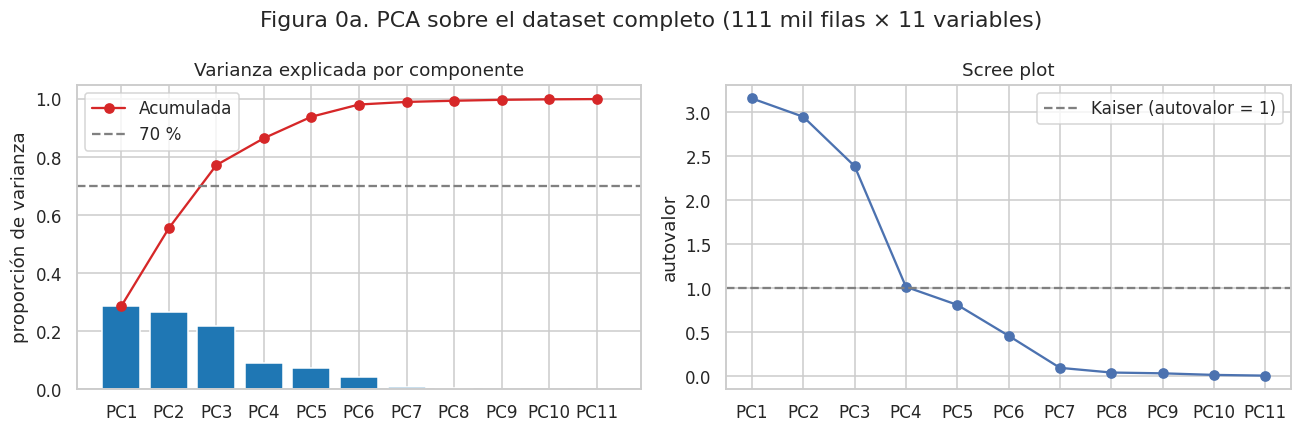

In [ ]:
NUM_ALL = ['año', 'superficie_sembrada_ha', 'superficie_cosechada_ha', 'produccion_tm', 'rendimiento_kgxha'] + CLIMA
LOGV = ['superficie_sembrada_ha', 'superficie_cosechada_ha', 'produccion_tm', 'rendimiento_kgxha']
Xall = df[NUM_ALL].dropna().copy()
for c in LOGV: Xall[c] = np.log1p(Xall[c])
Xall_s = StandardScaler().fit_transform(Xall)
print(f'Filas usadas: {len(Xall):,} (se excluyen las de 1981-1983 sin radiación) | variables: {Xall.shape[1]}')

pca_all = PCA(random_state=SEED).fit(Xall_s)
v = pca_all.explained_variance_ratio_
t_all = pd.DataFrame({'Desvío estándar': np.sqrt(pca_all.explained_variance_), 'Autovalor': pca_all.explained_variance_,
                      'Prop. varianza': v, 'Prop. acumulada': v.cumsum()}, index=[f'PC{i+1}' for i in range(len(v))])
display(t_all.style.format('{:.3f}').background_gradient(subset=['Prop. varianza'], cmap='Blues'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(t_all.index, v, color='tab:blue'); ax[0].plot(t_all.index, v.cumsum(), 'o-', color='tab:red', label='Acumulada'); ax[0].axhline(0.7, ls='--', color='gray', label='70 %')
ax[0].set_ylabel('proporción de varianza'); ax[0].legend(); ax[0].set_title('Varianza explicada por componente')
ax[1].plot(t_all.index, pca_all.explained_variance_, 'o-'); ax[1].axhline(1, ls='--', color='gray', label='Kaiser (autovalor = 1)'); ax[1].set_ylabel('autovalor'); ax[1].legend(); ax[1].set_title('Scree plot')
plt.suptitle('Figura 0a. PCA sobre el dataset completo (111 mil filas × 11 variables)'); plt.tight_layout(); plt.show()

,PC1,PC2,PC3,PC4
año,+0.19,+0.04,-0.16,-0.56
superficie_sembrada_ha,+0.47,-0.02,-0.10,-0.35
superficie_cosechada_ha,+0.55,-0.01,-0.09,+0.02
produccion_tm,+0.55,-0.01,-0.08,+0.14
rendimiento_kgxha,+0.33,-0.01,+0.00,+0.68
T2M,+0.01,+0.58,+0.04,+0.02
T2M_MAX,+0.01,+0.56,-0.14,-0.04
T2M_MIN,+0.01,+0.57,+0.08,+0.04
ALLSKY_SFC_SW_DWN,-0.14,-0.05,-0.51,+0.24
RH2M,+0.12,-0.11,+0.59,-0.10


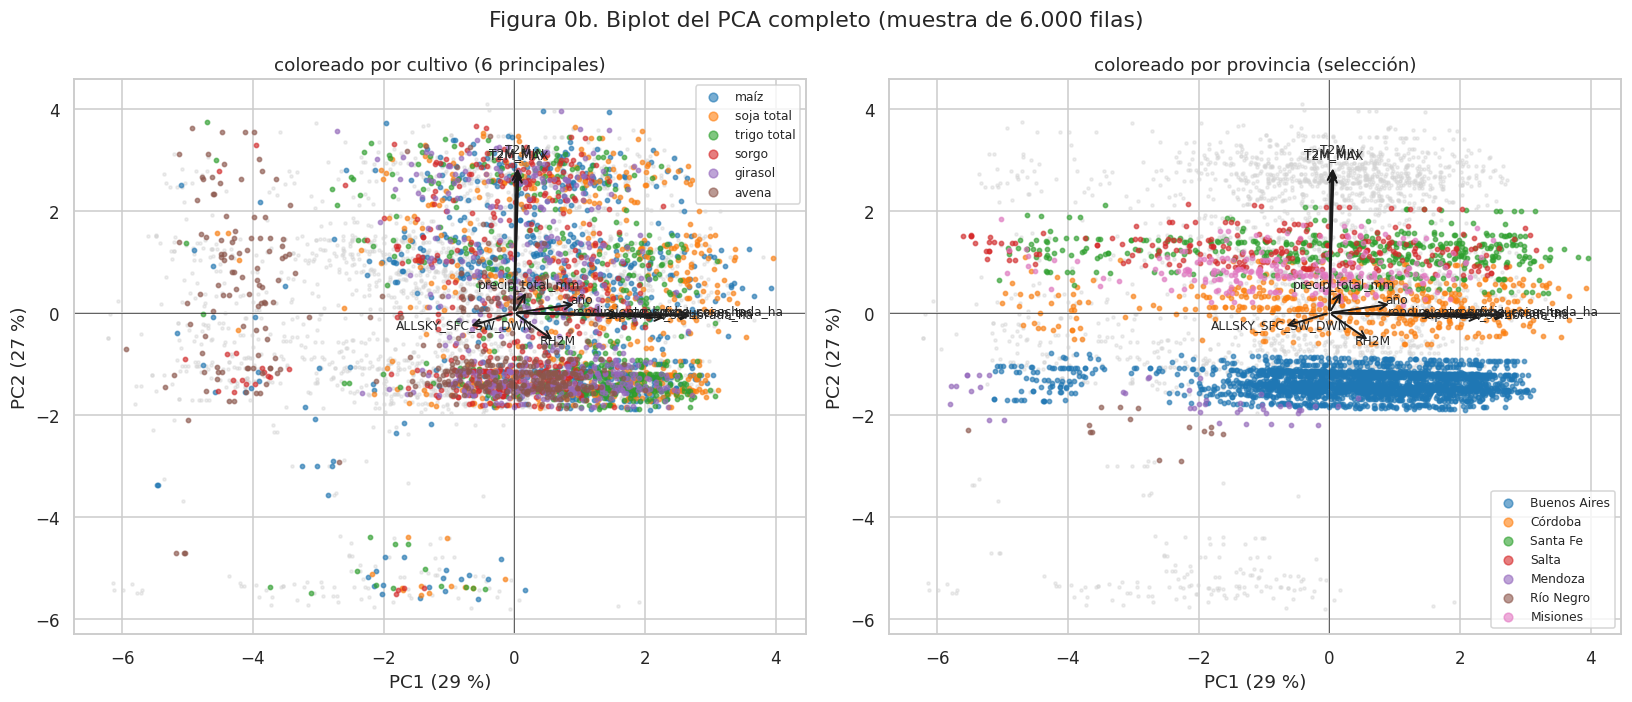

In [ ]:
load_all = pd.DataFrame(pca_all.components_.T, index=NUM_ALL, columns=t_all.index)
display(load_all[['PC1', 'PC2', 'PC3', 'PC4']].style.format('{:+.2f}').background_gradient(cmap='coolwarm', vmin=-0.7, vmax=0.7))

# Biplot sobre una muestra (con 111 mil puntos sería una mancha); cargas y varianza se calculan con todo
sc_all = pd.DataFrame(pca_all.transform(Xall_s)[:, :3], index=Xall.index, columns=['PC1', 'PC2', 'PC3'])
muestra = sc_all.sample(6000, random_state=SEED)
meta = df.loc[muestra.index, ['cultivo', 'provincia']]
top_cult = df['cultivo'].value_counts().index[:6]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, col, cats, tit in [(axes[0], 'cultivo', top_cult, 'coloreado por cultivo (6 principales)'), (axes[1], 'provincia', ['Buenos Aires', 'Córdoba', 'Santa Fe', 'Salta', 'Mendoza', 'Río Negro', 'Misiones'], 'coloreado por provincia (selección)')]:
    ax.scatter(muestra['PC1'], muestra['PC2'], s=4, color='lightgray', alpha=.4)
    for c, k in zip(cats, sns.color_palette('tab10', len(cats))):
        m = meta[col] == c; ax.scatter(muestra.loc[m, 'PC1'], muestra.loc[m, 'PC2'], s=8, alpha=.6, color=k, label=c)
    for vname in NUM_ALL:
        ax.annotate('', xy=(load_all.loc[vname, 'PC1']*5, load_all.loc[vname, 'PC2']*5), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k', lw=1.3))
        ax.text(load_all.loc[vname, 'PC1']*5.4, load_all.loc[vname, 'PC2']*5.4, vname, fontsize=8, ha='center')
    ax.axhline(0, color='k', lw=.4); ax.axvline(0, color='k', lw=.4); ax.legend(fontsize=8, markerscale=2)
    ax.set_xlabel(f'PC1 ({v[0]*100:.0f} %)'); ax.set_ylabel(f'PC2 ({v[1]*100:.0f} %)'); ax.set_title(tit)
plt.suptitle('Figura 0b. Biplot del PCA completo (muestra de 6.000 filas)'); plt.tight_layout(); plt.show()

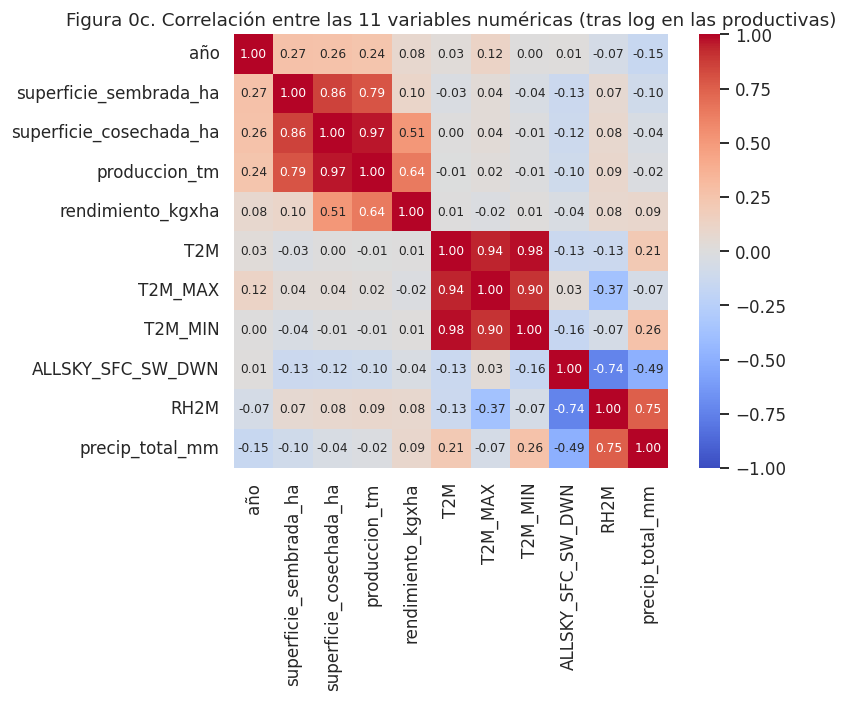

In [ ]:
# Correlación entre bloques: ¿el bloque productivo y el climático son independientes?
bloques = pd.DataFrame(Xall_s, columns=NUM_ALL).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(bloques, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax, annot_kws={'size': 8})
ax.set_title('Figura 0c. Correlación entre las 11 variables numéricas (tras log en las productivas)'); plt.tight_layout(); plt.show()

### 1.2 Lectura del PCA completo y consecuencias para el clustering

- **Hacen falta 3 componentes para superar el 70 %** de la varianza (77 %) y Kaiser retiene 4 (PC4 tiene autovalor 1,02). El dataset completo es mucho menos "comprimible" que el clima solo, porque mezcla fenómenos distintos, y las tres primeras componentes reparten la varianza casi por igual (29 %, 27 %, 22 %).
- **PC1 es un eje de escala productiva**: superficie sembrada, cosechada y producción cargan juntas y con el mismo signo (correlaciones de 0,8 a 0,97 entre sí, Figura 0c). Separa departamentos-cultivo grandes de chicos y no contiene clima (cargas de las climáticas ≈ 0).
- **PC2 es la temperatura** (las tres temperaturas con cargas ≈ 0,57) y **PC3 es el eje seco–húmedo** (humedad y precipitación contra radiación). Son exactamente los dos ejes que reaparecen en la sección 3 al hacer PCA solo con el clima; en el biplot por provincia (Figura 0b) se ve que las provincias se ordenan a lo largo de PC2: Buenos Aires y Río Negro abajo (frías), Salta y Misiones arriba (cálidas).
- **El rendimiento no forma parte del bloque climático**: su correlación lineal con cada variable climática es ≈ 0. Carga moderadamente en PC1 (por construcción, porque producción = rendimiento × superficie) y tiene una dimensión propia, PC4, donde se contrapone con `año`. Esto es coherente con el modelo supervisado: el rendimiento depende del clima de forma **no lineal y mediada por el cultivo** (umbrales de temperatura, óptimo de lluvia), cosas que una correlación lineal no captura pero que LightGBM sí.
- **Los bloques productivo y climático son casi ortogonales** (correlaciones cruzadas entre −0,13 y 0,12, Figura 0c). Eso es exactamente lo que se buscaba confirmar.

**Consecuencia metodológica.** Si se clusterizaran las filas con las 11 variables, los grupos mezclarían "cuán grande es el departamento-cultivo" con "qué clima tiene" y no serían interpretables como regiones. Como el objetivo es definir **zonas agroclimáticas**, el clustering de las secciones siguientes se hace únicamente sobre el bloque climático, y a nivel de departamento (para no contar el mismo clima una vez por cada cultivo). El PCA exploratorio es lo que justifica esa decisión.

## 2. Preparación de datos para el clustering: unidad de análisis y escalado

### 2.1 Unidad de análisis

El dataset tiene una fila por cultivo × departamento × año, pero el clima es el mismo para todos los cultivos de un departamento en un año dado. Para definir **zonas agroclimáticas estables** la unidad natural es el **departamento**, caracterizado por su clima promedio en el período 1981–2024. Esto deja una matriz de 490 unidades departamento-provincia × 6 variables climáticas (hay 397 nombres de departamento distintos, pero varios se repiten entre provincias, por ejemplo "Capital" o "General San Martín", y cada uno tiene su propio clima), sin ninguna variable de rendimiento ni de cultivo: el agrupamiento es puramente climático y no "ve" la variable objetivo.

### 2.2 Escalado

Las variables tienen unidades y magnitudes muy distintas (precipitación en cientos de mm, temperatura en decenas de °C, radiación en kWh/m²/día). Sin escalar, la precipitación dominaría todas las distancias. Se estandariza cada variable a media 0 y desvío 1 con `StandardScaler`, exactamente como `scale()` en la clase.

In [ ]:
clima_dep = (df.groupby(['provincia', 'departamento'])[CLIMA].mean().dropna())
print(f'Departamentos con clima completo: {len(clima_dep)}')
display(clima_dep.describe().T[['mean', 'std', 'min', 'max']].rename(columns={'mean':'media','std':'desvío','min':'mín','max':'máx'}))

scaler = StandardScaler()
Xc = pd.DataFrame(scaler.fit_transform(clima_dep), index=clima_dep.index, columns=CLIMA)
print('\nVerificación del escalado (media ≈ 0, desvío ≈ 1):'); display(Xc.agg(['mean', 'std']).round(3))

Departamentos con clima completo: 490


,media,desvío,mín,máx
T2M,16.733,4.073,5.700,24.292
T2M_MAX,30.831,4.322,12.450,38.528
T2M_MIN,4.378,3.610,-5.267,10.434
ALLSKY_SFC_SW_DWN,18.191,1.537,12.270,22.448
RH2M,63.186,10.248,38.881,83.180
precip_total_mm,854.945,407.228,121.269,"1,963.995"



Verificación del escalado (media ≈ 0, desvío ≈ 1):


,T2M,T2M_MAX,T2M_MIN,ALLSKY_SFC_SW_DWN,RH2M,precip_total_mm
mean,0.000,-0.000,0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001


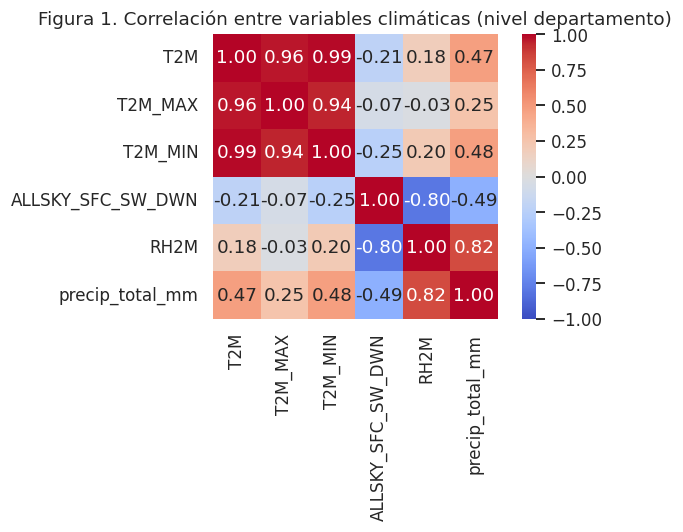

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(clima_dep.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Figura 1. Correlación entre variables climáticas (nivel departamento)'); plt.tight_layout(); plt.show()

**Lectura.** Las tres temperaturas están fuertemente correlacionadas entre sí y con la radiación; la humedad relativa y la precipitación forman un segundo bloque. Esta redundancia es justamente lo que PCA aprovecha: seis variables, pero probablemente dos o tres dimensiones reales.

## 3. Reducción de dimensiones con PCA sobre el clima departamental

,Desvío estándar,Autovalor,Prop. varianza,Prop. acumulada
PC1,1.857,3.450,0.574,0.574
PC2,1.416,2.005,0.334,0.907
PC3,0.695,0.483,0.080,0.988
PC4,0.214,0.046,0.008,0.995
PC5,0.163,0.027,0.004,1.000
PC6,0.049,0.002,0.000,1.000


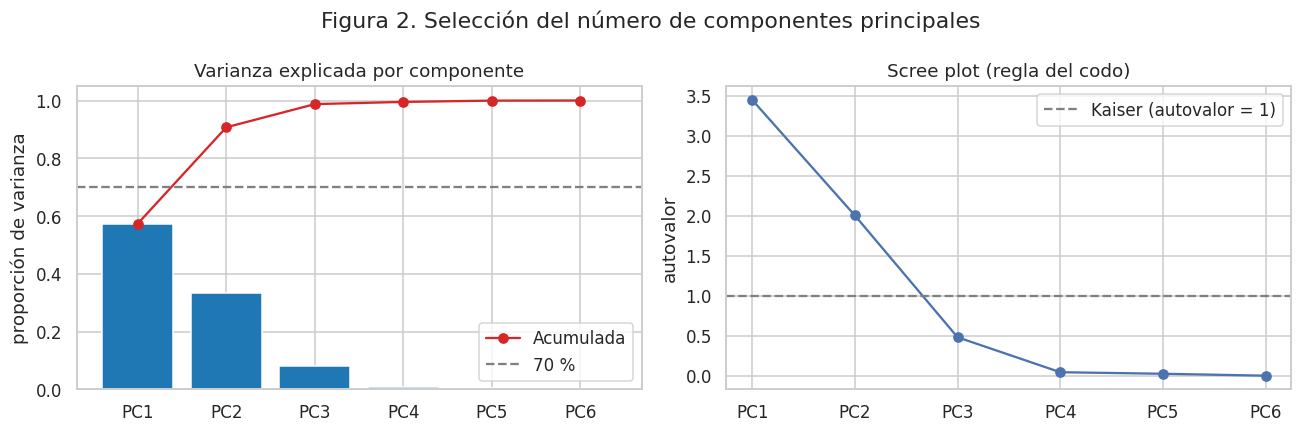

In [ ]:
pca = PCA(random_state=SEED).fit(Xc)
var = pca.explained_variance_ratio_
tabla_pca = pd.DataFrame({'Desvío estándar': np.sqrt(pca.explained_variance_), 'Autovalor': pca.explained_variance_,
                          'Prop. varianza': var, 'Prop. acumulada': var.cumsum()}, index=[f'PC{i+1}' for i in range(len(var))])
display(tabla_pca.style.format('{:.3f}'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(tabla_pca.index, var, color='tab:blue'); ax[0].plot(tabla_pca.index, var.cumsum(), 'o-', color='tab:red', label='Acumulada')
ax[0].axhline(0.7, ls='--', color='gray', label='70 %'); ax[0].set_ylabel('proporción de varianza'); ax[0].legend(); ax[0].set_title('Varianza explicada por componente')
ax[1].plot(tabla_pca.index, pca.explained_variance_, 'o-'); ax[1].axhline(1, ls='--', color='gray', label='Kaiser (autovalor = 1)'); ax[1].set_ylabel('autovalor'); ax[1].legend(); ax[1].set_title('Scree plot (regla del codo)')
plt.suptitle('Figura 2. Selección del número de componentes principales'); plt.tight_layout(); plt.show()

**Cuántas componentes elegir.** Se aplican los tres criterios vistos en clase:
- **Varianza acumulada > 70 %**: se alcanza con las dos primeras componentes.
- **Criterio de Kaiser** (autovalor > 1): retiene PC1 y PC2 (PC3 queda por debajo de 1).
- **Regla del codo**: la caída pronunciada ocurre después de PC2.

Los tres coinciden: **dos componentes** resumen el clima departamental. Se usan PC1 y PC2 para visualizar y PC1–PC3 para el clustering (conserva algo más de información sin agregar ruido).

,PC1,PC2,PC3
T2M,+0.494,-0.281,-0.007
T2M_MAX,+0.431,-0.410,-0.129
T2M_MIN,+0.496,-0.260,-0.045
ALLSKY_SFC_SW_DWN,-0.283,-0.480,+0.732
RH2M,+0.297,+0.577,+0.093
precip_total_mm,+0.394,+0.349,+0.661


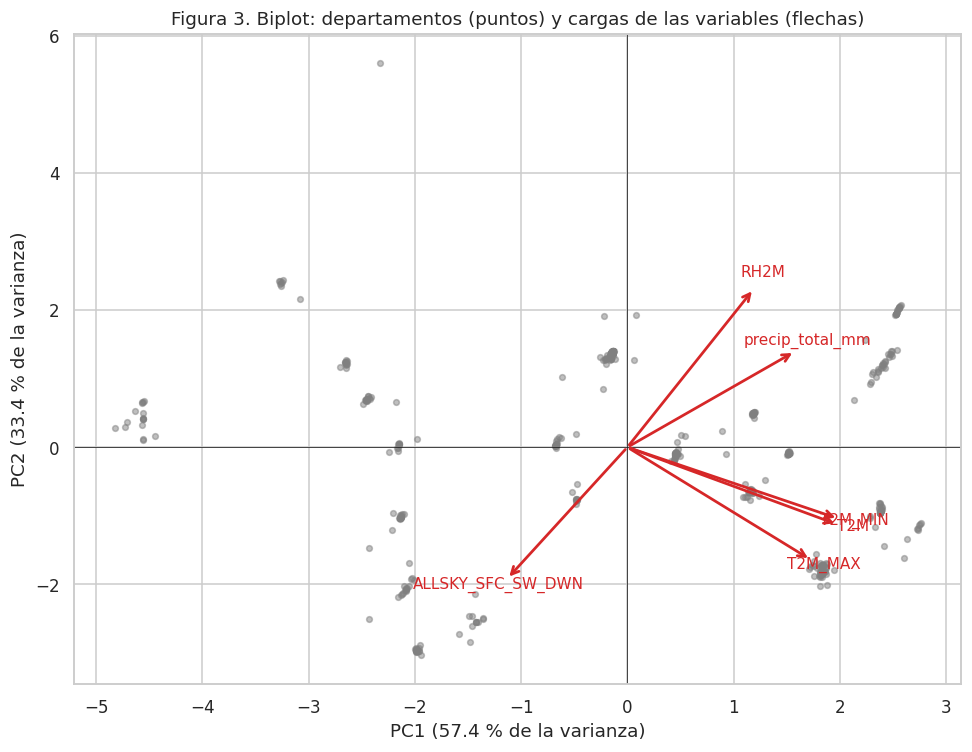

In [ ]:
loadings = pd.DataFrame(pca.components_.T, index=CLIMA, columns=tabla_pca.index)
display(loadings[['PC1', 'PC2', 'PC3']].style.format('{:+.3f}').background_gradient(cmap='coolwarm', vmin=-0.7, vmax=0.7))

scores = pd.DataFrame(pca.transform(Xc), index=Xc.index, columns=tabla_pca.index)
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(scores['PC1'], scores['PC2'], s=14, alpha=.5, color='gray')
for v in CLIMA:
    ax.annotate('', xy=(loadings.loc[v, 'PC1']*4, loadings.loc[v, 'PC2']*4), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:red', lw=1.8))
    ax.text(loadings.loc[v, 'PC1']*4.3, loadings.loc[v, 'PC2']*4.3, v, color='tab:red', fontsize=10, ha='center')
ax.axhline(0, color='k', lw=.5); ax.axvline(0, color='k', lw=.5)
ax.set_xlabel(f'PC1 ({var[0]*100:.1f} % de la varianza)'); ax.set_ylabel(f'PC2 ({var[1]*100:.1f} % de la varianza)')
ax.set_title('Figura 3. Biplot: departamentos (puntos) y cargas de las variables (flechas)'); plt.tight_layout(); plt.show()

**Interpretación de las componentes.**
- **PC1** (57 % de la varianza) carga positivamente sobre las tres temperaturas y, en menor medida, sobre precipitación y humedad, y negativamente sobre la radiación: es un eje **frío → cálido** que, geográficamente, va del sur al norte del país (el norte es más cálido y a la vez más lluvioso).
- **PC2** (33 %) contrapone humedad relativa y precipitación (cargas positivas) contra radiación solar y temperatura máxima (negativas): es un eje **seco y soleado → húmedo y nuboso**, que en Argentina corresponde al gradiente oeste–este (Cuyo y la Puna en un extremo, el litoral en el otro).

Con dos componentes se conserva el 91 % de la información original.

Estas dos dimensiones son exactamente las que un agrónomo usaría para describir el clima del país: temperatura y disponibilidad de agua.

## 4. Clustering jerárquico

Se aplica clustering aglomerativo con distancia euclidiana y enlace de Ward (`ward.D2` en la clase), que en cada paso fusiona los dos grupos cuya unión aumenta menos la varianza interna. El dendrograma permite ver la estructura completa y sugiere cuántos grupos naturales hay.

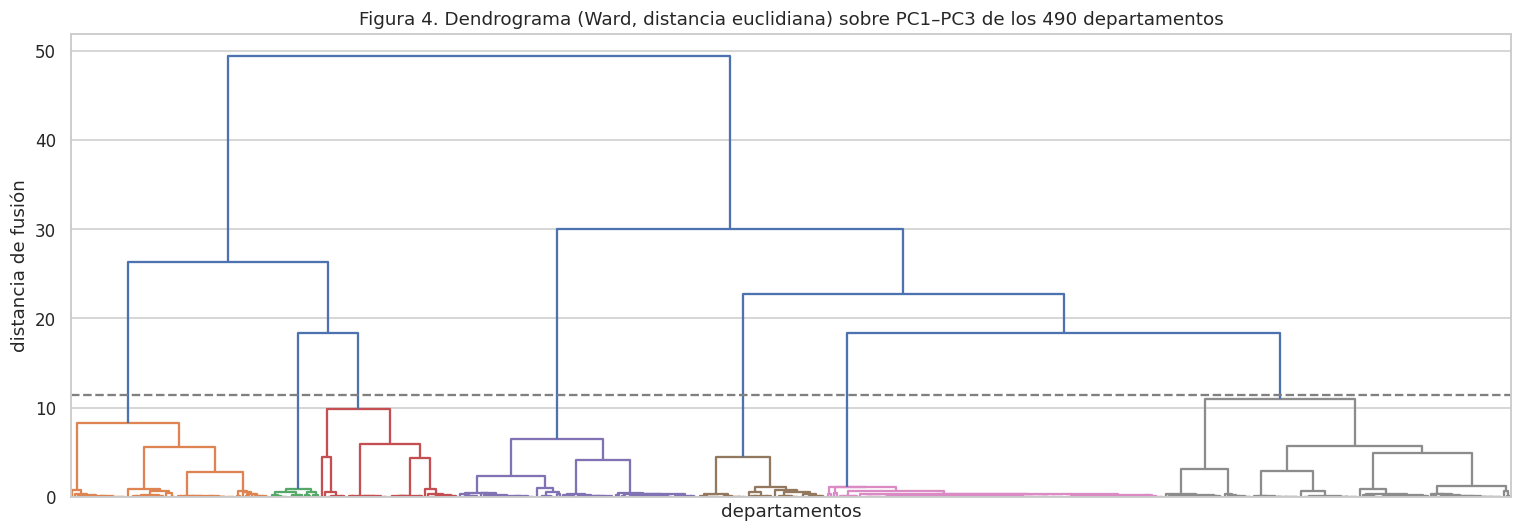

Altura de las últimas fusiones (cuánto "cuesta" pasar de k+1 a k grupos):


,de k+1 a k,altura de fusión
0,2 → 1,49.43
1,3 → 2,30.00
2,4 → 3,26.35
3,5 → 4,22.75
4,6 → 5,18.37
5,7 → 6,18.32
6,8 → 7,10.96
7,9 → 8,9.90


In [ ]:
Xpc = scores[['PC1', 'PC2', 'PC3']].values
Z = linkage(Xpc, method='ward')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=0.5*Z[-4, 2], ax=ax)   # colorea al nivel de ~5 grupos
ax.axhline(0.5*Z[-4, 2], ls='--', color='gray')
ax.set_title('Figura 4. Dendrograma (Ward, distancia euclidiana) sobre PC1–PC3 de los 490 departamentos'); ax.set_ylabel('distancia de fusión'); ax.set_xlabel('departamentos')
plt.tight_layout(); plt.show()

print('Altura de las últimas fusiones (cuánto "cuesta" pasar de k+1 a k grupos):')
display(pd.DataFrame({'de k+1 a k': [f'{k+1} → {k}' for k in range(1, 9)], 'altura de fusión': Z[-1:-9:-1, 2]}).style.format({'altura de fusión': '{:.2f}'}))

**Lectura.** Las fusiones más costosas son las últimas: el salto mayor aparece al pasar de 2 a 1 grupo (49) y de 3 a 2 (30); luego las alturas bajan gradualmente (26, 23, 18, 18) y caen a 11 al pasar de 7 a 6. Eso indica que a partir de 6–7 grupos las fusiones son "baratas" (grupos parecidos entre sí) y que la estructura fuerte está entre **3 y 6 zonas**. K-Means permitirá afinar esa elección con criterios cuantitativos.

## 5. K-Means: elección del número de clusters

Se ejecuta K-Means (con `n_init = 25`, igual que `nstart = 25` en la clase) para K = 2…10 y se calculan la inercia intra-grupo (para el método del codo) y el coeficiente de silhouette promedio.

,Inercia intra-grupo,Silhouette medio
K,,
2,"1,680.8",0.472
3,"1,108.6",0.468
4,828.9,0.488
5,559.1,0.573
6,390.3,0.609
7,282.5,0.626
8,221.0,0.637
9,172.7,0.670
10,145.6,0.673


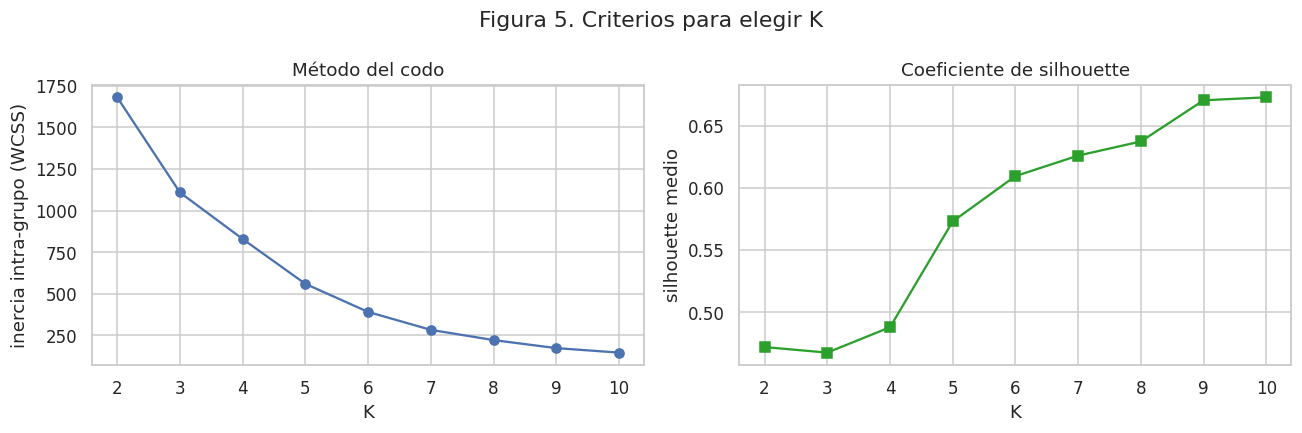

In [ ]:
Ks = range(2, 11); inercia, sil = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(Xpc)
    inercia.append(km.inertia_); sil.append(silhouette_score(Xpc, km.labels_))
tabla_k = pd.DataFrame({'K': list(Ks), 'Inercia intra-grupo': inercia, 'Silhouette medio': sil}).set_index('K')
display(tabla_k.style.format({'Inercia intra-grupo': '{:,.1f}', 'Silhouette medio': '{:.3f}'}).background_gradient(subset=['Silhouette medio'], cmap='Greens'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(Ks), inercia, 'o-'); ax[0].set_xlabel('K'); ax[0].set_ylabel('inercia intra-grupo (WCSS)'); ax[0].set_title('Método del codo')
ax[1].plot(list(Ks), sil, 's-', color='tab:green'); ax[1].set_xlabel('K'); ax[1].set_ylabel('silhouette medio'); ax[1].set_title('Coeficiente de silhouette')
plt.suptitle('Figura 5. Criterios para elegir K'); plt.tight_layout(); plt.show()

K elegido = 5 | silhouette medio = 0.573 | inercia intra = 559.1 | inercia inter = 2,344.4


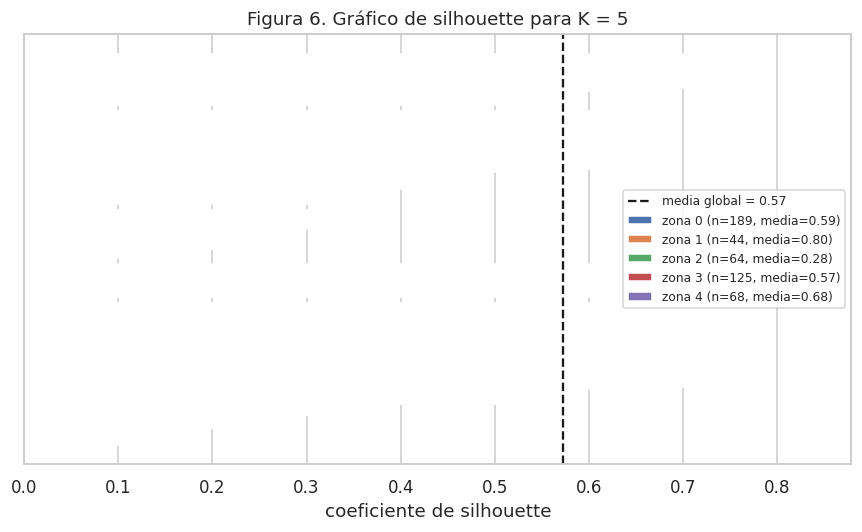

In [ ]:
K_OPT = 5
km = KMeans(n_clusters=K_OPT, n_init=25, random_state=SEED).fit(Xpc)
clima_dep['zona'] = km.labels_; scores['zona'] = km.labels_
sil_vals = silhouette_samples(Xpc, km.labels_)
print(f'K elegido = {K_OPT} | silhouette medio = {sil_vals.mean():.3f} | inercia intra = {km.inertia_:,.1f} | inercia inter = {((Xpc - Xpc.mean(0))**2).sum() - km.inertia_:,.1f}')

fig, ax = plt.subplots(figsize=(8, 5)); y0 = 0
for z in range(K_OPT):
    v = np.sort(sil_vals[km.labels_ == z]); ax.barh(np.arange(y0, y0+len(v)), v, height=1, label=f'zona {z} (n={len(v)}, media={v.mean():.2f})'); y0 += len(v) + 8
ax.axvline(sil_vals.mean(), ls='--', color='k', label=f'media global = {sil_vals.mean():.2f}'); ax.set_xlabel('coeficiente de silhouette'); ax.set_yticks([]); ax.legend(fontsize=8)
ax.set_title(f'Figura 6. Gráfico de silhouette para K = {K_OPT}'); plt.tight_layout(); plt.show()

**Justificación de K = 5.** Los criterios no señalan un único K, así que se combinan:
- **Codo**: la inercia cae con fuerza hasta K = 5 (de 1.681 a 559) y después la reducción por cluster adicional es cada vez menor.
- **Silhouette**: crece de forma casi monótona con K, lo que es típico cuando las unidades vienen en "paquetes" naturalmente compactos (los departamentos de una misma provincia tienen climas casi idénticos, así que cuantos más clusters, más se parecen a las provincias). Por eso el silhouette no puede usarse solo. Sí muestra un **salto claro entre K = 4 (0,49) y K = 5 (0,57)**, y a partir de ahí mejoras pequeñas.
- **Dendrograma**: estructura fuerte entre 3 y 6 grupos.
- **Interpretabilidad**: K = 5 produce zonas que coinciden con las regiones agroclimáticas conocidas del país (sección 6), mientras que K = 4 fusiona regiones muy distintas (la Patagonia con la Puna jujeña) y K = 6 empieza a separar provincias individuales.

Como se indica en la clase, la elección final del K queda a criterio del analista combinando los criterios cuantitativos con la interpretabilidad.

## 6. Interpretación de las zonas agroclimáticas

,T2M,T2M_MAX,T2M_MIN,ALLSKY_SFC_SW_DWN,RH2M,precip_total_mm,n_departamentos
zona,,,,,,,
0,15.8,29.7,3.4,17.5,69.0,913.6,189
1,20.0,31.5,7.5,17.0,78.2,1778.6,44
2,9.4,23.4,-1.9,18.6,57.6,479.3,64
3,21.6,36.2,8.7,17.9,61.9,938.4,125
4,15.3,30.5,3.0,20.9,44.9,294.4,68


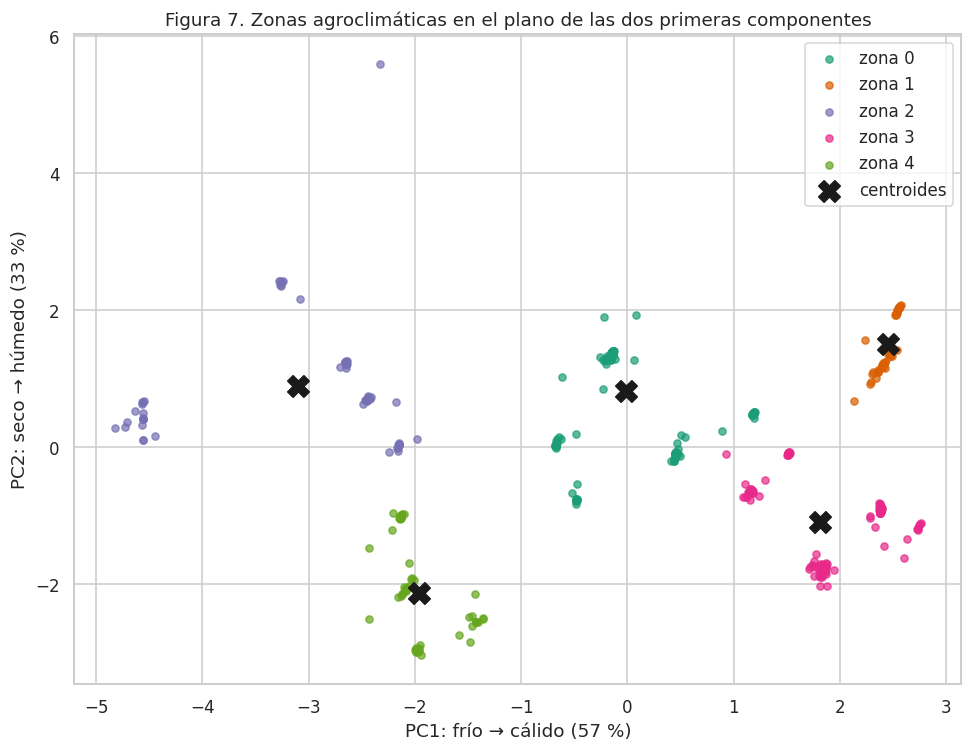

In [ ]:
centroides = clima_dep.groupby('zona')[CLIMA].mean()
centroides['n_departamentos'] = clima_dep.groupby('zona').size()
display(centroides.round(1).style.format({c: '{:.1f}' for c in CLIMA}).background_gradient(subset=CLIMA, cmap='coolwarm'))

fig, ax = plt.subplots(figsize=(9, 7))
pal = sns.color_palette('Dark2', K_OPT)
for z in range(K_OPT):
    s = scores[scores.zona == z]; ax.scatter(s['PC1'], s['PC2'], s=22, alpha=.7, color=pal[z], label=f'zona {z}')
cen_pc = pca.transform(scaler.transform(centroides[CLIMA]))
ax.scatter(cen_pc[:, 0], cen_pc[:, 1], marker='X', s=200, color='k', label='centroides')
ax.set_xlabel(f'PC1: frío → cálido ({var[0]*100:.0f} %)'); ax.set_ylabel(f'PC2: seco → húmedo ({var[1]*100:.0f} %)'); ax.legend()
ax.set_title('Figura 7. Zonas agroclimáticas en el plano de las dos primeras componentes'); plt.tight_layout(); plt.show()

In [ ]:
comp = pd.crosstab(clima_dep.reset_index()['provincia'], clima_dep['zona'].values)
comp.columns = [f'zona {c}' for c in comp.columns]
comp['zona dominante'] = comp.idxmax(axis=1)
display(comp.sort_values('zona dominante'))

,zona 0,zona 1,zona 2,zona 3,zona 4,zona dominante
provincia,,,,,,
Buenos Aires,114,0,0,0,0,zona 0
Córdoba,27,0,0,0,0,zona 0
Entre Ríos,17,0,0,0,0,zona 0
La Pampa,21,0,0,0,0,zona 0
San Luis,10,0,0,0,0,zona 0
Corrientes,0,26,0,0,0,zona 1
Misiones,0,18,0,0,0,zona 1
Chubut,0,0,12,0,0,zona 2
Santa Cruz,0,0,8,0,0,zona 2


**Lectura de las zonas.** Combinando los centroides con las provincias que contiene cada grupo (la numeración de K-Means es arbitraria; los nombres se asignan por interpretación):

| Zona | Nombre descriptivo | Clima del centroide | Provincias dominantes |
|---|---|---|---|
| 0 | **Templada húmeda (pampeana)** | 15,8 °C, 914 mm, HR 69 % | Buenos Aires, Córdoba, Entre Ríos, La Pampa, San Luis |
| 1 | **Subtropical húmeda (Mesopotamia)** | 20,0 °C, 1.779 mm, HR 78 % | Misiones, Corrientes |
| 2 | **Fría (Patagonia y Puna)** | 9,4 °C, 479 mm, mínimas bajo 0 | Chubut, Neuquén, Río Negro, Santa Cruz, Tierra del Fuego, Jujuy |
| 3 | **Cálida subhúmeda (NOA y Chaco)** | 21,6 °C, máximas 36 °C, 938 mm | Salta, Tucumán, Santiago del Estero, Chaco, Formosa, Santa Fe |
| 4 | **Árida (Cuyo)** | 15,3 °C, 294 mm, HR 45 %, máxima radiación | Mendoza, San Juan, La Rioja, Catamarca |

El algoritmo, sin ninguna información geográfica ni de rendimiento, recupera las grandes regiones agroclimáticas conocidas del país. Que la partición coincida con el conocimiento agronómico es la mejor validación externa posible de un método no supervisado. El único agrupamiento discutible es Jujuy con la Patagonia: ambos son fríos y secos en promedio anual (por la altura en un caso y la latitud en el otro), aunque agronómicamente sean muy distintos; separarlos requeriría K = 6 o variables de altitud.

## 7. Integración con el modelo supervisado

Se evalúa si la zona agroclimática aporta información al modelo ganador del entregable supervisado (LightGBM optimizado, mismos hiperparámetros, misma partición 80/20 estratificada por cultivo). Se comparan dos versiones: **sin zona** (modelo original) y **con zona** (se agrega la etiqueta de cluster como variable categórica). Además se analiza el error del modelo por zona.

In [ ]:
# --- misma preparación que en el notebook supervisado ---
d = df[df['superficie_cosechada_ha'] > 0].copy()
d['log_sup_sembrada'] = np.log1p(d['superficie_sembrada_ha']); d['log_sup_cosechada'] = np.log1p(d['superficie_cosechada_ha'])
d['ratio_cosechada'] = (d['superficie_cosechada_ha'] / d['superficie_sembrada_ha'].replace(0, np.nan)).clip(upper=1.5)
d['amplitud_termica'] = d['T2M_MAX'] - d['T2M_MIN']
d = d.merge(clima_dep[['zona']].reset_index(), on=['provincia', 'departamento'], how='left')
d['zona'] = d['zona'].fillna(-1).astype(int)          # -1: departamentos sin clima completo (no clusterizados)
NUM = ['año', 'log_sup_sembrada', 'log_sup_cosechada', 'ratio_cosechada', 'T2M', 'T2M_MAX', 'T2M_MIN', 'amplitud_termica', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'precip_total_mm']
y = np.log1p(d['rendimiento_kgxha'])

def preparar(X_tr, X_te, y_tr, ohe):
    Xtr = pd.get_dummies(X_tr, columns=ohe, dtype=float); Xte = pd.get_dummies(X_te, columns=ohe, dtype=float).reindex(columns=Xtr.columns, fill_value=0.0)
    te = TargetEncoder(target_type='continuous', cv=5, random_state=SEED)
    Xtr['departamento'] = te.fit_transform(X_tr[['departamento']], y_tr)[:, 0]; Xte['departamento'] = te.transform(X_te[['departamento']])[:, 0]
    med = Xtr.median(); return Xtr.fillna(med), Xte.fillna(med)

def metricas(yt_log, yp_log):
    yt, yp = np.expm1(yt_log), np.expm1(np.clip(yp_log, 0, 14))
    return {'MAE': mean_absolute_error(yt, yp), 'RMSE': np.sqrt(mean_squared_error(yt, yp)), 'R²': r2_score(yt, yp)}

params = dict(subsample=1.0, reg_lambda=0, num_leaves=255, n_estimators=800, min_child_samples=10, learning_rate=0.1, colsample_bytree=0.8, subsample_freq=1, random_state=SEED, verbose=-1)
kf = KFold(5, shuffle=True, random_state=SEED); res = {}; pred = {}
for nombre, cols, ohe in [('Sin zona', ['cultivo', 'provincia', 'departamento'] + NUM, ['cultivo', 'provincia']),
                          ('Con zona', ['cultivo', 'provincia', 'departamento', 'zona'] + NUM, ['cultivo', 'provincia', 'zona'])]:
    X = d[cols]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=SEED, stratify=d['cultivo'])
    Xtr, Xte = preparar(X_tr, X_te, y_tr, ohe)
    t0 = time.time(); m = lgb.LGBMRegressor(**params).fit(Xtr, y_tr); t = time.time() - t0
    cv = cross_val_score(lgb.LGBMRegressor(**params), Xtr, y_tr, cv=kf, scoring='r2')
    r = metricas(y_te, m.predict(Xte)); r.update({'R² CV (log)': cv.mean(), '± CV': cv.std(), 'Tiempo (s)': t}); res[nombre] = r
    pred[nombre] = np.expm1(m.predict(Xte)); modelo_zona = m; Xte_zona = Xte
tabla = pd.DataFrame(res).T
display(tabla.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R²': '{:.4f}', 'R² CV (log)': '{:.4f}', '± CV': '{:.4f}', 'Tiempo (s)': '{:.1f}'}))

,MAE,RMSE,R²,R² CV (log),± CV,Tiempo (s)
Sin zona,500,"1,276",0.9419,0.9011,0.0053,6.9
Con zona,496,"1,269",0.9426,0.9019,0.0057,7.1


,n,rend_medio,MAE,sesgo,MAE relativo (%)
zona,,,,,
0,11989,"3,012",412,-63,13.7
1,1875,"5,144",696,-36,13.5
2,573,"7,882","1,118",-213,14.2
3,5868,"4,240",500,-71,11.8
4,582,"8,914",910,-239,10.2


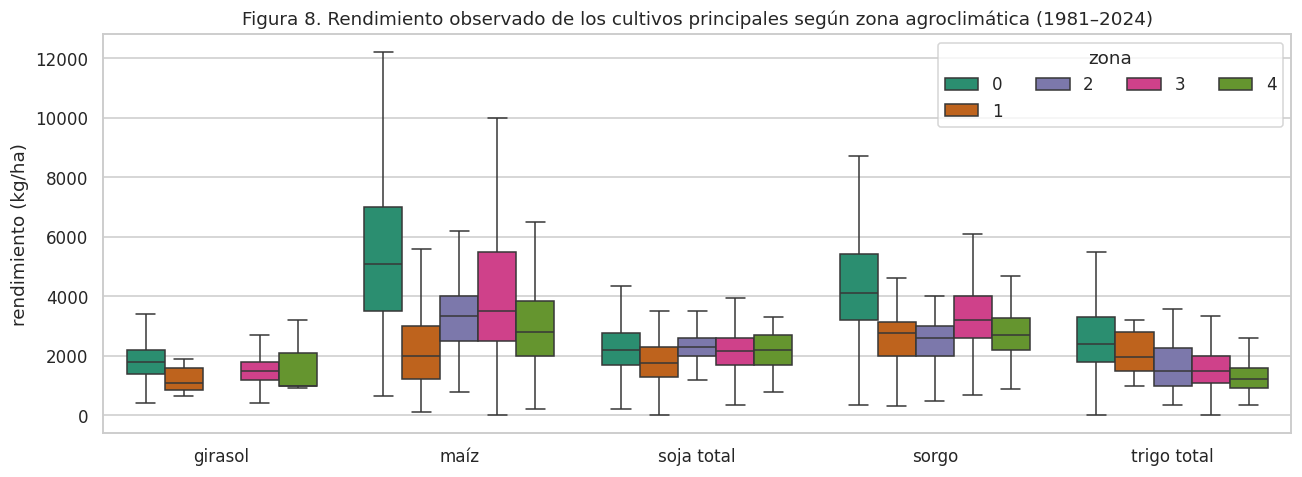

In [ ]:
# Error del modelo (con zona) por zona agroclimática, en el conjunto de prueba
yt = np.expm1(y_te).values; yp = pred['Con zona']
err = pd.DataFrame({'zona': X_te['zona'].values, 'cultivo': X_te['cultivo'].values, 'real': yt, 'abs_err': np.abs(yt - yp), 'err': yp - yt})
por_zona = err[err.zona >= 0].groupby('zona').agg(n=('real', 'size'), rend_medio=('real', 'mean'), MAE=('abs_err', 'mean'), sesgo=('err', 'mean'))
por_zona['MAE relativo (%)'] = por_zona['MAE'] / por_zona['rend_medio'] * 100
display(por_zona.style.format({'rend_medio': '{:,.0f}', 'MAE': '{:,.0f}', 'sesgo': '{:+,.0f}', 'MAE relativo (%)': '{:.1f}'}))

# Rendimiento observado por zona para los cultivos principales
principales = ['soja total', 'maíz', 'trigo total', 'girasol', 'sorgo']
sub = d[(d.cultivo.isin(principales)) & (d.zona >= 0)]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=sub, x='cultivo', y='rendimiento_kgxha', hue='zona', palette='Dark2', showfliers=False, ax=ax)
ax.set_ylabel('rendimiento (kg/ha)'); ax.set_xlabel(''); ax.legend(title='zona', ncol=4)
ax.set_title('Figura 8. Rendimiento observado de los cultivos principales según zona agroclimática (1981–2024)'); plt.tight_layout(); plt.show()

**Lectura.** La zona agroclimática ordena claramente los rendimientos de los cultivos extensivos (Figura 8): la misma soja o el mismo maíz rinden sistemáticamente distinto según la zona, lo que confirma que los grupos encontrados son agronómicamente significativos. Sin embargo, al agregar la zona como variable al modelo supervisado la mejora es **prácticamente nula** (R² 0,9419 → 0,9426 en prueba, MAE 500 → 496 kg/ha; en validación cruzada 0,9011 → 0,9019, diferencia menor que el desvío entre folds). Es el resultado esperable: el modelo ya dispone de las variables climáticas crudas y del departamento, y la zona es una **función determinística de esas mismas variables**, así que un modelo de árboles puede reconstruirla por sí solo. El valor de la zona no está en mejorar la predicción sino en la **interpretación**: la tabla de error por zona muestra que el error relativo es parejo entre regiones (10–14 % del rendimiento medio), con el mejor desempeño en Cuyo y el NOA y el peor en la zona fría, donde hay pocos datos (573 filas de prueba) y cultivos de alto rendimiento bajo riego (papa, cebolla, ajo) muy variables. Además, en todas las zonas el sesgo es levemente negativo: el modelo tiende a subestimar un poco, más en las zonas de rendimientos altos. Resumir el comportamiento del modelo en cinco regiones con sentido es mucho más comunicable que hacerlo en 490 departamentos.

## 8. Conclusiones

1. **El problema principal es supervisado; el no supervisado es su complemento.** Con `rendimiento_kgxha` disponible, la predicción y la explicación del rendimiento se resuelven con regresión supervisada. El aprendizaje no supervisado responde una pregunta distinta, descriptiva: cómo se estructura el clima del país.
2. **PCA reduce las seis variables climáticas a dos dimensiones interpretables** (frío → cálido y seco/soleado → húmedo/nuboso) que concentran el 91 % de la varianza y coinciden con los ejes que usa la agronomía para describir ambientes.
3. **K-Means con K = 5 recupera las regiones agroclimáticas conocidas** (pampeana templada húmeda, Mesopotamia subtropical, NOA/Chaco cálida, Cuyo árida, Patagonia/Puna fría) sin usar geografía ni rendimiento. El dendrograma, el codo y el salto del silhouette en K = 5 respaldan la elección, junto con la interpretabilidad.
4. **La zona no mejora la predicción pero sí la comunicación de resultados**: la Figura 8 y la tabla de error por zona son la forma más clara de mostrarle a un productor o a un tomador de decisiones dónde el modelo es confiable y cómo se comporta cada cultivo según el ambiente.
5. **Trabajo futuro**: clusterizar con clima mensual (capturaría estacionalidad, no solo promedios anuales), probar DBSCAN o K-Medoids para detectar departamentos atípicos, y agrupar cultivos según su respuesta al clima (clustering sobre los valores SHAP del modelo supervisado), lo que permitiría recomendaciones por familia de cultivos.